In [1]:
#
# This is a sample Notebook to demonstrate how to read "MNIST Dataset"
#
import numpy as np # linear algebra
import struct
from array import array
from os.path  import join

#
# MNIST Data Loader Class
#
class MnistDataloader(object):
    def __init__(self, training_images_filepath,training_labels_filepath,
                 test_images_filepath, test_labels_filepath):
        self.training_images_filepath = training_images_filepath
        self.training_labels_filepath = training_labels_filepath
        self.test_images_filepath = test_images_filepath
        self.test_labels_filepath = test_labels_filepath

    def read_images_labels(self, images_filepath, labels_filepath):
        labels = []
        with open(labels_filepath, 'rb') as file:
            magic, size = struct.unpack(">II", file.read(8))
            if magic != 2049:
                raise ValueError('Magic number mismatch, expected 2049, got {}'.format(magic))
            labels = array("B", file.read())

        with open(images_filepath, 'rb') as file:
            magic, size, rows, cols = struct.unpack(">IIII", file.read(16))
            if magic != 2051:
                raise ValueError('Magic number mismatch, expected 2051, got {}'.format(magic))
            image_data = array("B", file.read())
        images = []
        for i in range(size):
            images.append([0] * rows * cols)
        for i in range(size):
            img = np.array(image_data[i * rows * cols:(i + 1) * rows * cols])
            img = img.reshape(28, 28)
            images[i][:] = img

        return images, labels

    def load_data(self):
        x_train, y_train = self.read_images_labels(self.training_images_filepath, self.training_labels_filepath)
        x_test, y_test = self.read_images_labels(self.test_images_filepath, self.test_labels_filepath)
        return (x_train, y_train),(x_test, y_test)



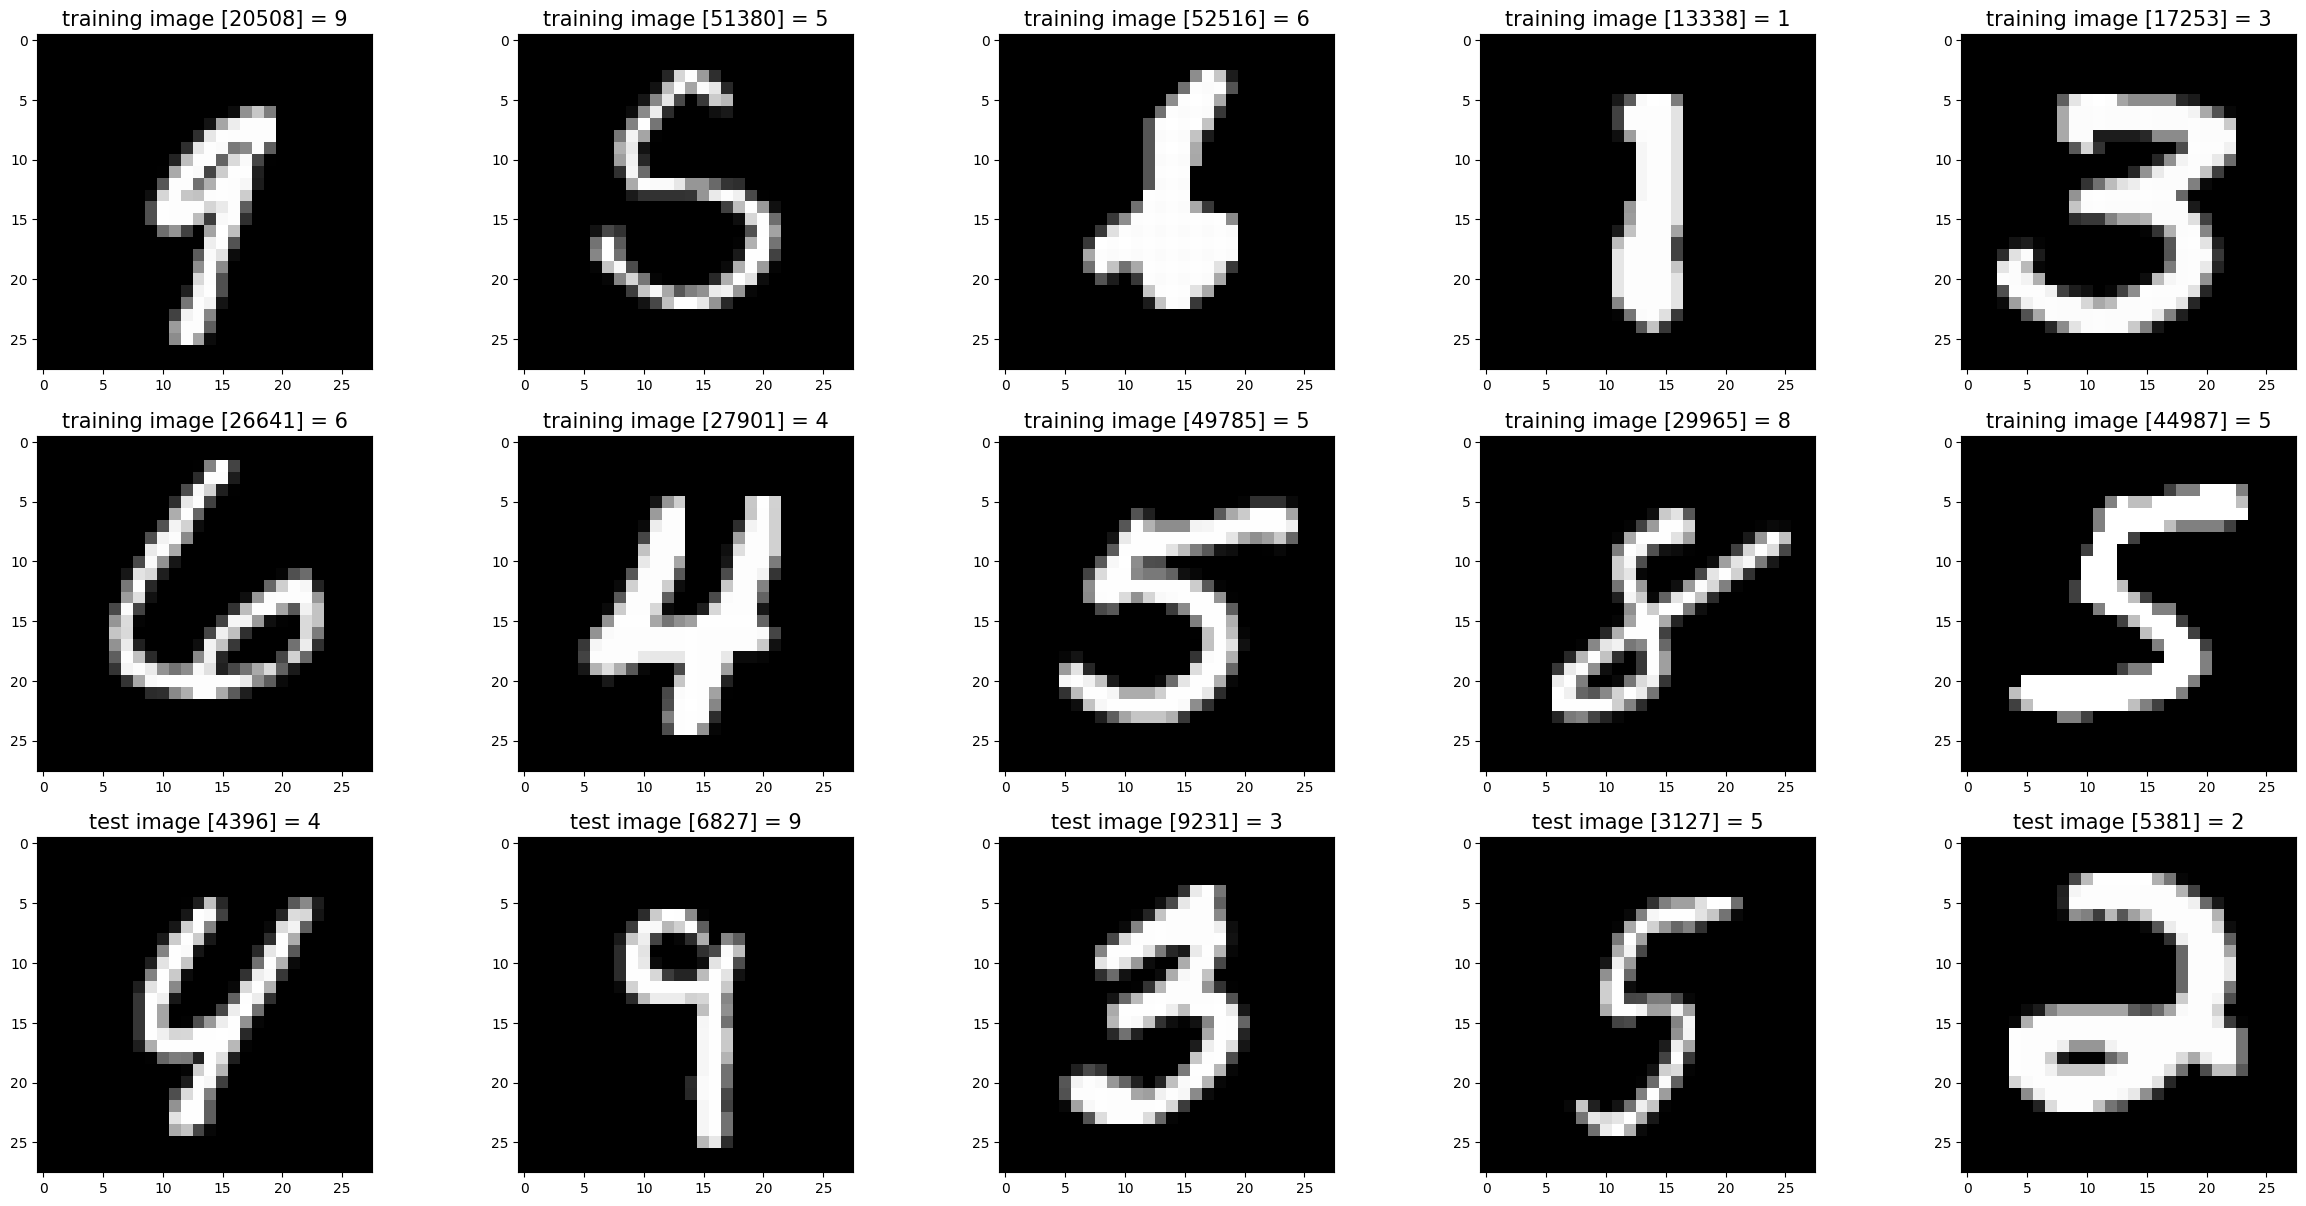

In [4]:
#
# Verify Reading Dataset via MnistDataloader class
#
%matplotlib inline
import random
import matplotlib.pyplot as plt

#
# Set file paths based on added MNIST Datasets
#
input_path = '/content'
training_images_filepath = '/content/train-images.idx3-ubyte'
training_labels_filepath = '/content/train-labels.idx1-ubyte'
test_images_filepath = '/content/t10k-images.idx3-ubyte'
test_labels_filepath = '/content/t10k-labels.idx1-ubyte'

#
# Helper function to show a list of images with their relating titles
#
def show_images(images, title_texts):
    cols = 5
    rows = int(len(images)/cols) + 1
    plt.figure(figsize=(30,20))
    index = 1
    for x in zip(images, title_texts):
        image = x[0]
        title_text = x[1]
        plt.subplot(rows, cols, index)
        plt.imshow(image, cmap=plt.cm.gray)
        if (title_text != ''):
            plt.title(title_text, fontsize = 15);
        index += 1

#
# Load MINST dataset
#
mnist_dataloader = MnistDataloader(training_images_filepath, training_labels_filepath, test_images_filepath, test_labels_filepath)
(x_train, y_train), (x_test, y_test) = mnist_dataloader.load_data()

#
# Show some random training and test images
#
images_2_show = []
titles_2_show = []
for i in range(0, 10):
    r = random.randint(0, len(x_train)-1)
    images_2_show.append(x_train[r])
    titles_2_show.append('training image [' + str(r) + '] = ' + str(y_train[r]))

for i in range(0, 5):
    r = random.randint(0, len(x_test)-1)
    images_2_show.append(x_test[r])
    titles_2_show.append('test image [' + str(r) + '] = ' + str(y_test[r]))

show_images(images_2_show, titles_2_show)

In [7]:
import numpy as np

#convert the dataset lists into NumPy arrays
x_train = np.array(x_train)
y_train = np.array(y_train)
x_test = np.array(x_test)
y_test = np.array(y_test)

# Check the MNIST dataset
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Test images shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000, 28, 28)


In [8]:
# step2:Prepare the MNIST images

import numpy as np

# Normalize pixel values from 0–255 to 0–1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Training labels: (60000,)
Testing labels: (10000, 28, 28)


In [9]:
# Step 3: Build a neural network

import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Step 4: Train the model

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8810 - loss: 0.4193 - val_accuracy: 0.9555 - val_loss: 0.1710
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9419 - loss: 0.2011 - val_accuracy: 0.9673 - val_loss: 0.1236
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9559 - loss: 0.1509 - val_accuracy: 0.9725 - val_loss: 0.1018
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9645 - loss: 0.1225 - val_accuracy: 0.9738 - val_loss: 0.0915
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9703 - loss: 0.1037 - val_accuracy: 0.9770 - val_loss: 0.0833


In [12]:
# ==========================================
# STEP 1: CHECK THE MNIST DATASET
# ==========================================

import numpy as np

# Check that the dataset variables exist
print("Checking MNIST dataset...")

print("\nOriginal dataset information:")
print("Training images type:", type(x_train))
print("Training labels type:", type(y_train))
print("Test images type:", type(x_test))
print("Test labels type:", type(y_test))

# Convert all lists or existing arrays into NumPy arrays
x_train = np.asarray(x_train)
y_train = np.asarray(y_train)
x_test = np.asarray(x_test)
y_test = np.asarray(y_test)

# Display dataset shapes
print("\nDataset shapes:")
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Test images shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

# Display data types
print("\nDataset data types:")
print("x_train:", x_train.dtype)
print("y_train:", y_train.dtype)
print("x_test:", x_test.dtype)
print("y_test:", y_test.dtype)

# Check whether the shapes are correct
print("\nChecking dataset dimensions:")

if x_train.shape == (60000, 28, 28):
    print("Training images: OK")
else:
    print("Training images: CHECK SHAPE")

if y_train.shape == (60000,):
    print("Training labels: OK")
else:
    print("Training labels: CHECK SHAPE")

if x_test.shape == (10000, 28, 28):
    print("Test images: OK")
else:
    print("Test images: CHECK SHAPE")

if y_test.shape == (10000,):
    print("Test labels: OK")
else:
    print("Test labels: CHECK SHAPE")

Checking MNIST dataset...

Original dataset information:
Training images type: <class 'numpy.ndarray'>
Training labels type: <class 'numpy.ndarray'>
Test images type: <class 'numpy.ndarray'>
Test labels type: <class 'numpy.ndarray'>

Dataset shapes:
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000, 28, 28)

Dataset data types:
x_train: float32
y_train: uint8
x_test: float32
y_test: uint8

Checking dataset dimensions:
Training images: OK
Training labels: OK
Test images: OK
Test labels: CHECK SHAPE


In [13]:
# ==========================================
# STEP 2: PREPARE THE MNIST DATASET
# ==========================================

# Convert image pixels to floating-point numbers
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")

# Normalize pixel values from 0-255 to 0-1
if x_train.max() > 1:
    x_train = x_train / 255.0

if x_test.max() > 1:
    x_test = x_test / 255.0

# Ensure labels are integer class IDs (0-9)
y_train = y_train.astype("int64")
y_test = y_test.astype("int64")

# Print final dataset information
print("Final dataset information:")
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

print("\nPixel value range:")
print("Training images:", x_train.min(), "to", x_train.max())
print("Test images:", x_test.min(), "to", x_test.max())

# Validate labels
print("\nUnique training labels:", np.unique(y_train))
print("Unique test labels:", np.unique(y_test))

Final dataset information:
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000, 28, 28)

Pixel value range:
Training images: 0.0 to 1.0
Test images: 0.0 to 1.0

Unique training labels: [0 1 2 3 4 5 6 7 8 9]
Unique test labels: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176

In [14]:
# STEP 3: CHECK THE MODEL

print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

print("\nTraining images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Model input shape: (None, 28, 28)
Model output shape: (None, 10)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000, 28, 28)


In [17]:
# STEP 4: FIX TEST LABELS

import numpy as np

# Reload the correct test labels from the MNIST data loader
y_test = np.array(
    mnist_dataloader.read_images_labels(
        mnist_dataloader.test_images_filepath,
        mnist_dataloader.test_labels_filepath
    )[1]
)

print("Test labels shape:", y_test.shape)
print("First 10 test labels:", y_test[:10])

Test labels shape: (10000,)
First 10 test labels: [7 2 1 0 4 1 4 9 5 9]


In [18]:
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [19]:
# STEP 5: EVALUATE THE MODEL

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Test loss:", test_loss)
print("Test accuracy:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9720 - loss: 0.0929
Test loss: 0.09294167906045914
Test accuracy: 97.2 %


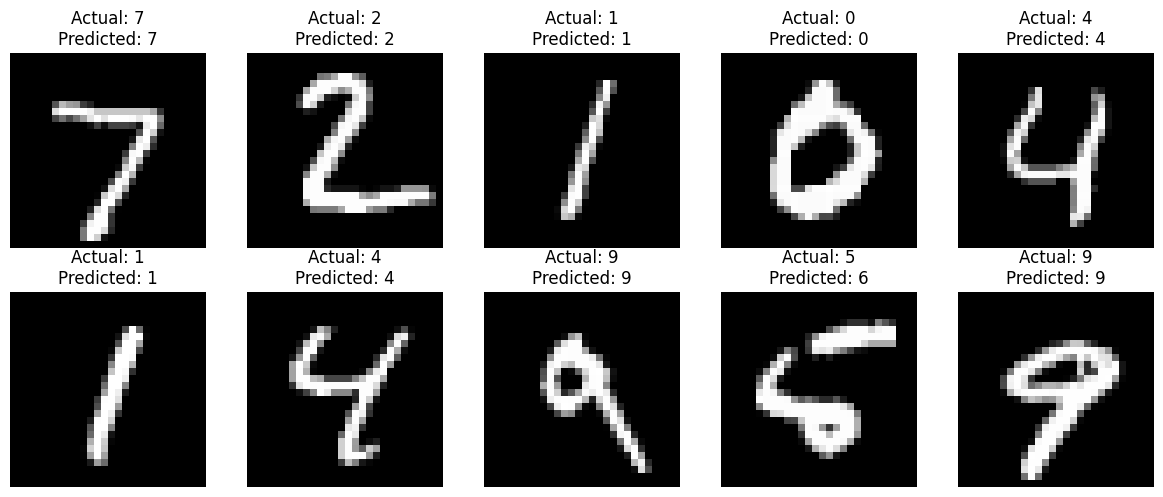

In [20]:
# STEP 6: PREDICT HANDWRITTEN DIGITS

import numpy as np
import matplotlib.pyplot as plt

# Predict the first 10 test images
predictions = model.predict(x_test[:10], verbose=0)

# Get the digit with the highest probability
predicted_labels = np.argmax(predictions, axis=1)

# Display actual and predicted digits
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(
        f"Actual: {y_test[i]}\n"
        f"Predicted: {predicted_labels[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

Actual digit: 6
Predicted digit: 6
Confidence: 99.71 %


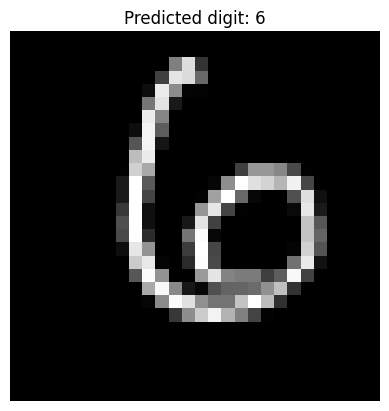

In [21]:
# STEP 7: TEST ONE IMAGE

index = 100

image = x_test[index]
prediction = model.predict(
    image.reshape(1, 28, 28),
    verbose=0
)

predicted_digit = np.argmax(prediction[0])

print("Actual digit:", y_test[index])
print("Predicted digit:", predicted_digit)
print(
    "Confidence:",
    round(float(np.max(prediction[0])) * 100, 2),
    "%"
)

plt.imshow(image, cmap="gray")
plt.title(f"Predicted digit: {predicted_digit}")
plt.axis("off")
plt.show()

In [22]:
# STEP 8: SAVE THE MODEL

model.save("/content/mnist_digit_model.keras")

print("Model saved successfully!")

Model saved successfully!


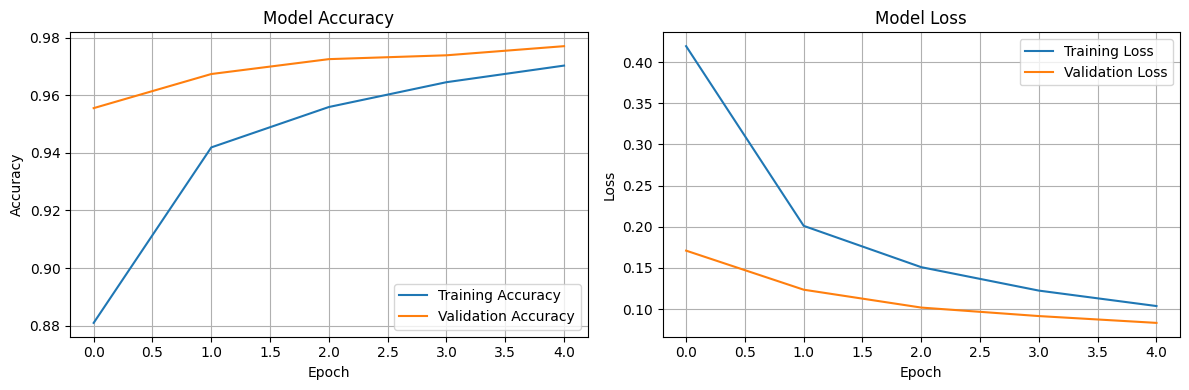

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


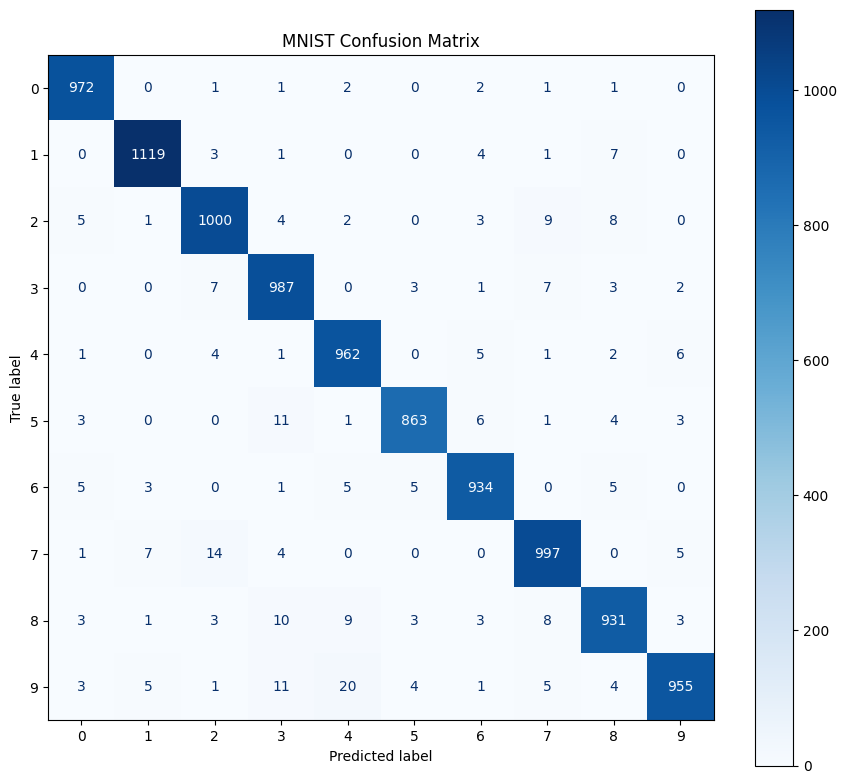

Classification Report:
              precision    recall  f1-score   support

           0     0.9789    0.9918    0.9853       980
           1     0.9850    0.9859    0.9855      1135
           2     0.9681    0.9690    0.9685      1032
           3     0.9573    0.9772    0.9672      1010
           4     0.9610    0.9796    0.9702       982
           5     0.9829    0.9675    0.9751       892
           6     0.9739    0.9749    0.9744       958
           7     0.9680    0.9698    0.9689      1028
           8     0.9648    0.9559    0.9603       974
           9     0.9805    0.9465    0.9632      1009

    accuracy                         0.9720     10000
   macro avg     0.9720    0.9718    0.9719     10000
weighted avg     0.9721    0.9720    0.9720     10000



In [23]:
# STEP 9: TRAINING GRAPHS AND CONFUSION MATRIX

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# A. Training and validation graphs
if "history" in globals() and hasattr(history, "history"):
    h = history.history

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(h["accuracy"], label="Training Accuracy")
    if "val_accuracy" in h:
        plt.plot(h["val_accuracy"], label="Validation Accuracy")
    plt.title("Model Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(h["loss"], label="Training Loss")
    if "val_loss" in h:
        plt.plot(h["val_loss"], label="Validation Loss")
    plt.title("Model Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()
else:
    print("Training history is unavailable.")
    print("See Step 2 below to save it during training.")

# B. Predict digits from test images
y_true = np.asarray(y_test)

if y_true.ndim == 2 and y_true.shape[1] == 10:
    y_true = np.argmax(y_true, axis=1)

y_true = y_true.reshape(-1).astype(int)

predictions = model.predict(x_test, verbose=1)
y_pred = np.argmax(predictions, axis=1)

# C. Display confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=np.arange(10))

fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("MNIST Confusion Matrix")
plt.tight_layout()
plt.show()

# D. Classification report
print("Classification Report:")
print(classification_report(
    y_true, y_pred,
    labels=np.arange(10),
    digits=4,
    zero_division=0
))

In [24]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9662 - loss: 0.1094 - val_accuracy: 0.9760 - val_loss: 0.0788
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9730 - loss: 0.0839 - val_accuracy: 0.9787 - val_loss: 0.0718
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9777 - loss: 0.0708 - val_accuracy: 0.9785 - val_loss: 0.0756
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9792 - loss: 0.0637 - val_accuracy: 0.9795 - val_loss: 0.0703
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9816 - loss: 0.0563 - val_accuracy: 0.9803 - val_loss: 0.0686
